# Final Evaluation

This notebook evaluates the **frozen Bayesian network models** on the held-out test set. It is the final predictive evaluation stage: model structures and parameters have already been selected using training data and cross-validation.

| § | What | Why |
|---|---|---|
| 1 | Load the held-out split and frozen models | Ensure every model is evaluated on the same unseen songs |
| 2 | Compute exact predictive distributions | Obtain \(P(\text{popularity} \mid \text{the other nine variables})\) for each test song |
| 3 | Test metrics and bootstrap confidence intervals | Quantify predictive performance and uncertainty |
| 4 | Paired model comparisons | Compare models on identical bootstrap resamples |
| 5 | Generalization gap | Contrast training-CV performance with held-out test performance |
| 6 | Confusion matrices and prediction distributions | Show which popularity bins are confused or over/under-predicted |
| 7 | Report-ready figure | Summarize test accuracy and log-loss with 95% confidence intervals |

**Test-set discipline.** `test.csv` is used only in this notebook, for final evaluation. No graph is relearned, no hyperparameter is retuned, and no primary model is reselected based on test performance. The primary model was fixed using training-set cross-validation in the parameter-learning stage.

## Setup and configuration

First, we import the evaluation utilities, load the frozen parameter configuration, and define the popularity-bin order. Keeping this order fixed ensures that predictions, confusion matrices, and plots all use the same low-to-high class ordering.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from bn_structures import load_split
from parameter_inference import (
    TARGET, SEED, fit_parameters, load_fitted_model, popularity_log_probabilities,
)

ROOT = Path.cwd()
assert (ROOT / "models/parameter_config.json").is_file(), "Run from the repository root"
FIG_DIR = ROOT / "figures/evaluation"; FIG_DIR.mkdir(parents=True, exist_ok=True)

# Shared visual language with structure_learning: blue = model results, orange = primary/target.
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.titlesize": 10, "axes.labelsize": 9, "font.size": 9})
MODEL_DIR = ROOT / "models"

with open(MODEL_DIR / "parameter_config.json") as f:
    config = json.load(f)

# Popularity bins in ORDER (low -> high). Keep this order for every table and plot.
ORDER = ["(-0.001, 20.0]", "(20.0, 40.0]", "(40.0, 60.0]", "(60.0, 80.0]", "(80.0, 100.0]"]
assert list(config["state_names"][TARGET]) == ORDER, "State order changed; fix ORDER"
PRIMARY = config["primary_model_id"]
print("Primary model (fixed before testing):", PRIMARY)

Primary model (fixed before testing): HC start=hand


## 1. Load the held-out data and frozen models

Next, we load the shared train/test split and the already-fitted models. The training split is used only to construct the majority-class baseline; all reported predictive metrics below are computed on the held-out test split.

In [2]:
train, test = load_split()
print(f"train {len(train):,} songs | test {len(test):,} songs")
X_test = test.drop(columns=TARGET)
y = pd.Categorical(test[TARGET], categories=ORDER).codes
assert (y >= 0).all(), "Unknown popularity state in test set"

models = {name: load_fitted_model(ROOT / spec["model_path"])
          for name, spec in config["per_structure"].items()}

# Baseline: independent variables (empty graph), fit on TRAIN only, with light smoothing.
# Its P(popularity | features) is just the training marginal, so its argmax is the
# always-majority-class prediction and its log-loss is the "prior only" log-loss.
BASELINE = "Baseline: prior only (always majority bin)"
models[BASELINE] = fit_parameters(train, "Empty graph (prior only)", "BDeu", 1)

majority_bin = train[TARGET].mode()[0]
print(f"Majority bin in train: {majority_bin}  "
      f"({(train[TARGET] == majority_bin).mean():.1%} of train, "
      f"{(test[TARGET] == majority_bin).mean():.1%} of test)")

train 3,571 songs | test 893 songs
Majority bin in train: (40.0, 60.0]  (34.4% of train, 32.7% of test)


## 2. Exact predictive distributions

For each model, we compute the posterior probability of every popularity bin given the other nine variables. These are exact inference results, not hard class labels. We also calculate the joint log-probability of each complete song under each model; this is a separate measure from conditional popularity log-loss.

In [3]:
LOGP = {name: popularity_log_probabilities(m, X_test) for name, m in models.items()}
for name, lp in LOGP.items():
    assert np.isfinite(lp).all(), f"{name}: undefined or zero-probability rows on test"
    assert np.allclose(np.exp(lp).sum(1), 1), f"{name}: posteriors not normalized"


def joint_loglik(model, df):
    """Per-song log P(all 10 variables) under the model (sum of log CPT entries)."""
    total = np.zeros(len(df))
    for cpd in model.get_cpds():
        idx = []
        for v in cpd.variables:
            codes = pd.Categorical(df[v], categories=cpd.state_names[v]).codes
            assert (codes >= 0).all(), f"unknown state in {v}"
            idx.append(codes)
        total += np.log(cpd.values[tuple(idx)])
    return total


JOINT = {name: joint_loglik(m, test) for name, m in models.items()}

## 3. Test metrics and bootstrap confidence intervals

We summarize performance using accuracy, conditional log-loss, within-one-bin accuracy, mean absolute bin error, and joint log-likelihood per song. The 2,000 bootstrap samples are shared across models, so uncertainty estimates and later pairwise comparisons are paired.

In [4]:
N = len(y)
rng = np.random.default_rng(SEED)
B = 2000
BOOT = rng.integers(0, N, size=(B, N))          # same resamples for every model -> paired comparisons


def per_song(lp):
    pred = lp.argmax(1)
    return {"correct": (pred == y).astype(float),
            "nll": -lp[np.arange(N), y],
            "within1": (np.abs(pred - y) <= 1).astype(float),
            "bin_err": np.abs(pred - y).astype(float)}


PS = {name: per_song(lp) for name, lp in LOGP.items()}


def ci(values_by_song):
    boot = values_by_song[BOOT].mean(1)
    return values_by_song.mean(), *np.percentile(boot, [2.5, 97.5])


rows = []
for name, ps in PS.items():
    acc, acc_lo, acc_hi = ci(ps["correct"])
    nll, nll_lo, nll_hi = ci(ps["nll"])
    rows.append({"model": name,
                 "test_accuracy": acc, "acc_ci_lo": acc_lo, "acc_ci_hi": acc_hi,
                 "test_log_loss": nll, "ll_ci_lo": nll_lo, "ll_ci_hi": nll_hi,
                 "within_one_bin": ps["within1"].mean(),
                 "mean_abs_bin_error": ps["bin_err"].mean(),
                 "joint_loglik_per_song": JOINT[name].mean()})
results = pd.DataFrame(rows).set_index("model")
results.to_csv(MODEL_DIR / "test_results.csv")
print(results.round(4).to_string())

                                            test_accuracy  acc_ci_lo  acc_ci_hi  test_log_loss  ll_ci_lo  ll_ci_hi  within_one_bin  mean_abs_bin_error  joint_loglik_per_song
model                                                                                                                                                                        
HC + BIC                                           0.4434     0.4110     0.4759         1.3298    1.2886    1.3702          0.8387              0.7503               -13.2685
HC start=hand                                      0.4434     0.4099     0.4759         1.2984    1.2559    1.3401          0.8477              0.7357               -13.2444
Hand-designed                                      0.4345     0.4009     0.4658         1.3181    1.2744    1.3612          0.8376              0.7548               -13.3219
GES (BIC)                                          0.4434     0.4099     0.4759         1.2984    1.2559    1.3401          0.8477

## 4. Paired model comparisons

Compare each non-baseline model with both the prior-only baseline and the preselected primary model. Differences are calculated song-by-song and bootstrapped using the same resampled test indices. Negative log-loss differences favor the model in the first column; positive accuracy differences favor it.

In [5]:
paired = []
for name in PS:
    if name == BASELINE:
        continue
    for ref in [BASELINE, PRIMARY]:
        if name == ref:
            continue
        d_acc = PS[name]["correct"] - PS[ref]["correct"]
        d_nll = PS[name]["nll"] - PS[ref]["nll"]            # negative = better than ref
        b_acc, b_nll = d_acc[BOOT].mean(1), d_nll[BOOT].mean(1)
        paired.append({"model": name, "vs": ref,
                       "d_accuracy": d_acc.mean(), "d_acc_lo": np.percentile(b_acc, 2.5), "d_acc_hi": np.percentile(b_acc, 97.5),
                       "d_log_loss": d_nll.mean(), "d_ll_lo": np.percentile(b_nll, 2.5), "d_ll_hi": np.percentile(b_nll, 97.5)})
paired = pd.DataFrame(paired)
paired.to_csv(MODEL_DIR / "test_paired_differences.csv", index=False)
print(paired.round(4).to_string(index=False))
print("\nAn interval that excludes 0 means the difference is distinguishable from noise on this test set.")

        model                                         vs  d_accuracy  d_acc_lo  d_acc_hi  d_log_loss  d_ll_lo  d_ll_hi
     HC + BIC Baseline: prior only (always majority bin)      0.1165    0.0828    0.1512     -0.0496  -0.0745  -0.0256
     HC + BIC                              HC start=hand      0.0000   -0.0134    0.0134      0.0314   0.0142   0.0481
HC start=hand Baseline: prior only (always majority bin)      0.1165    0.0829    0.1478     -0.0811  -0.1083  -0.0537
Hand-designed Baseline: prior only (always majority bin)      0.1075    0.0739    0.1422     -0.0614  -0.0944  -0.0300
Hand-designed                              HC start=hand     -0.0090   -0.0314    0.0112      0.0197  -0.0045   0.0452
    GES (BIC) Baseline: prior only (always majority bin)      0.1165    0.0829    0.1478     -0.0811  -0.1083  -0.0537
    GES (BIC)                              HC start=hand      0.0000    0.0000    0.0000     -0.0000  -0.0000   0.0000
  Naive Bayes Baseline: prior only (always major

## 5. Generalization gap

Compare the parameter-learning stage's training cross-validation metrics with held-out test metrics. A larger test log-loss or lower test accuracy can indicate reduced generalization. The CV values are not fully independent of the final fitted graphs, so interpret the gap descriptively.

In [6]:
cv = {n: s for n, s in config["per_structure"].items()}
gap = pd.DataFrame({
    "cv_log_loss": {n: cv[n]["cv_log_loss"] for n in cv},
    "test_log_loss": {n: results.loc[n, "test_log_loss"] for n in cv},
    "cv_accuracy": {n: cv[n]["cv_accuracy"] for n in cv},
    "test_accuracy": {n: results.loc[n, "test_accuracy"] for n in cv},
})
gap["log_loss_gap"] = gap.test_log_loss - gap.cv_log_loss
print(gap.round(4).to_string())
print("Note: CV graphs were learned on all of train, so CV numbers are slightly optimistic.")

               cv_log_loss  test_log_loss  cv_accuracy  test_accuracy  log_loss_gap
HC + BIC            1.3300         1.3298       0.4626         0.4434       -0.0002
HC start=hand       1.3036         1.2984       0.4682         0.4434       -0.0053
Hand-designed       1.3176         1.3181       0.4592         0.4345        0.0004
GES (BIC)           1.3036         1.2984       0.4682         0.4434       -0.0053
Naive Bayes         1.3585         1.3335       0.4551         0.4513       -0.0250
Note: CV graphs were learned on all of train, so CV numbers are slightly optimistic.


## 6. Confusion matrices and predicted class distributions

The primary model's confusion matrix is shown as raw counts and row-normalized proportions. Additional model matrices are saved for appendix use. The predicted-bin distribution is also compared with the true test distribution to reveal systematic over- or under-prediction of popularity classes.

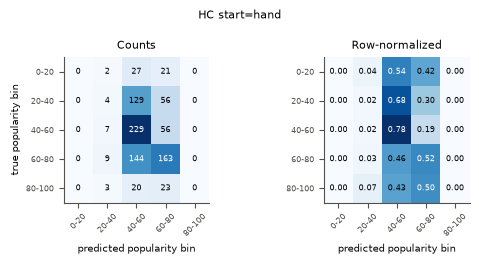

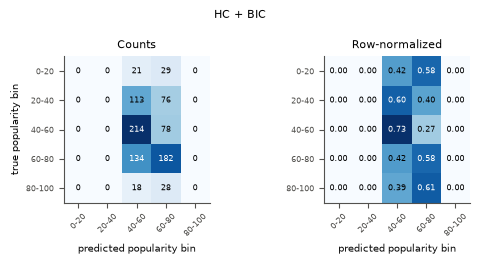

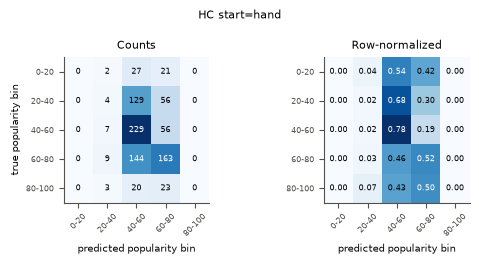

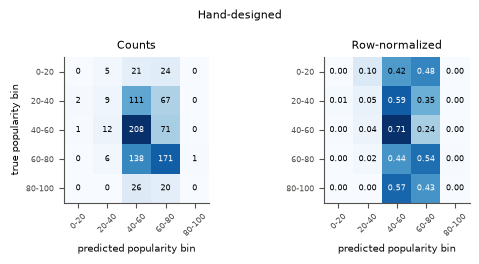

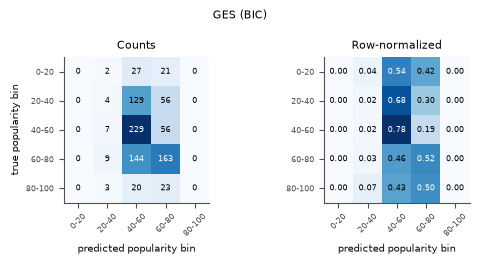

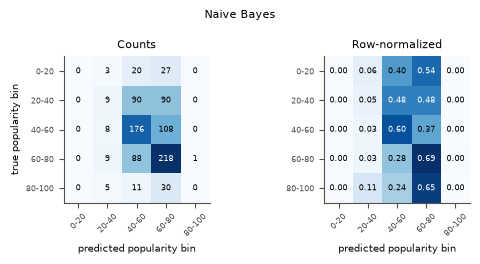


How often each model PREDICTS each bin (test):
                HC + BIC  HC start=hand  Hand-designed  GES (BIC)  Naive Bayes  Baseline: prior only (always majority bin)
(-0.001, 20.0]         0              0              3          0            0                                           0
(20.0, 40.0]           0             25             32         25           34                                           0
(40.0, 60.0]         500            549            504        549          385                                         893
(60.0, 80.0]         393            319            353        319          473                                           0
(80.0, 100.0]          0              0              1          0            1                                           0
True test distribution: [50, 189, 292, 316, 46]


In [7]:
def plot_confusion(name, path):
    pred = LOGP[name].argmax(1)
    cm = confusion_matrix(y, pred, labels=range(5))
    cm_row = cm / cm.sum(1, keepdims=True).clip(min=1)
    short = ["0-20", "20-40", "40-60", "60-80", "80-100"]
    fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6))
    for ax, mat, title, fmt in [(axes[0], cm, "Counts", "{:d}"), (axes[1], cm_row, "Row-normalized", "{:.2f}")]:
        ax.imshow(mat, cmap="Blues")
        for i in range(5):
            for j in range(5):
                v = mat[i, j]
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=6,
                        color="white" if v > mat.max() * 0.6 else "black")
        ax.set_xticks(range(5), short, fontsize=6, rotation=45)
        ax.set_yticks(range(5), short, fontsize=6)
        ax.set_xlabel("predicted popularity bin", fontsize=7)
        ax.set_title(title, fontsize=8)
    axes[0].set_ylabel("true popularity bin", fontsize=7)
    fig.suptitle(name, fontsize=8)
    plt.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight"); plt.show()
    return cm


cm_primary = plot_confusion(PRIMARY, FIG_DIR / "confusion_primary.png")
for name in config["per_structure"]:                      # the rest go to an appendix
    plot_confusion(name, FIG_DIR / f"confusion_{name.replace(' ', '_').replace('+', 'plus').replace('(', '').replace(')', '').replace('=', '-')}.png")

pred_dist = pd.DataFrame({name: np.bincount(LOGP[name].argmax(1), minlength=5) for name in LOGP}, index=ORDER)
print("\nHow often each model PREDICTS each bin (test):")
print(pred_dist.to_string())
print("True test distribution:", np.bincount(y, minlength=5).tolist())

## 7. Report-ready performance figure

Generate a compact figure comparing test accuracy and test log-loss across models, including percentile-bootstrap 95% confidence intervals. Accuracy is better when higher; log-loss is better when lower.

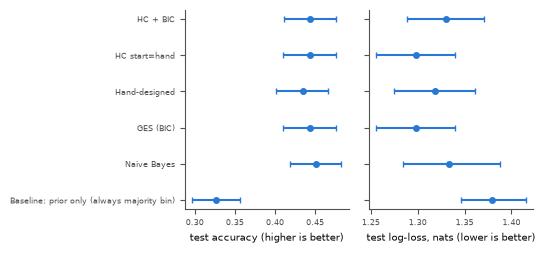

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6), sharey=True)
names = list(results.index)[::-1]
ypos = np.arange(len(names))
for ax, col, lo, hi, label in [(axes[0], "test_accuracy", "acc_ci_lo", "acc_ci_hi", "test accuracy (higher is better)"),
                               (axes[1], "test_log_loss", "ll_ci_lo", "ll_ci_hi", "test log-loss, nats (lower is better)")]:
    v = results.loc[names, col].to_numpy()
    err = np.vstack([v - results.loc[names, lo].to_numpy(), results.loc[names, hi].to_numpy() - v])
    ax.errorbar(v, ypos, xerr=err, fmt="o", ms=4, capsize=2, color="#2a78d6")
    ax.set_xlabel(label, fontsize=7); ax.tick_params(labelsize=6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(ypos, names, fontsize=6)
plt.tight_layout(); fig.savefig(FIG_DIR / "test_metrics.png", dpi=200, bbox_inches="tight"); plt.show()